# 0. Conectar y montar MyDrive

In [2]:
from google.colab import drive
import os

drive.mount('/content/drive')

mi_directorio = '/content/drive/MyDrive'
os.chdir(mi_directorio)

Mounted at /content/drive


# 1. Importar todas las librerias necesarias

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random
import string
import seaborn as sns

# 2. Inicializar algunas variables que después modificaremos

In [4]:
hostnames = []
dataset = []
df = None

# 3. Crear una función para generar los hostnames en base a unas reglas

In [5]:
def set_hostnames(number_of_hosts:int) -> None:
  hostname_os = ['L']*40 + ['S']*30 + ['A']*20 + ['H']*10
  hostname_environment = ['D']*10 + ['I']*10 + ['T']*25 + ['S']*25 + ['P']*30
  hostname_country = ['NOR']*6 + ['FRA']*9 + ['ITA']*16 + ['ESP']*16 + ['DEU']*23 + ['IRL']*30
  grupo_alpha = []

  for i in range(number_of_hosts):
    hostname = random.choice(hostname_os) + random.choice(hostname_environment) + random.choice(hostname_country)
    grupo_alpha.append(hostname)
    hostname += str(grupo_alpha.count(hostname)).zfill(3)
    hostnames.append(hostname)

# 4. Crear una función para obtener el nombre del SO

In [6]:
def get_os(hostname:str) -> str:
  if hostname.startswith('L'):
    return 'Linux'
  elif hostname.startswith('S'):
    return 'Solaris'
  elif hostname.startswith('A'):
    return 'AIX'
  elif hostname.startswith('H'):
    return 'HP-UX'
  else:
    return 'Unknow'

# 5. Crear una función para obtener el nombre del entorno

In [7]:
def get_environment(hostname:str) -> str:
  hostname_environment = hostname[1]

  if hostname_environment == 'D':
    return 'Development'
  elif hostname_environment == 'I':
    return 'Integration'
  elif hostname_environment == 'T':
    return 'Testing'
  elif hostname_environment == 'S':
    return 'Staging'
  elif hostname_environment == 'P':
    return 'Production'
  else:
    return 'Unknow'

# 6. Crear una función para obtener el nombre del país

In [8]:
def get_country(hostname:str) -> str:
  mascota_coutry = hostname[2:5]

  if mascota_coutry == 'NOR':
    return 'Norway'
  elif mascota_coutry == 'FRA':
    return 'France'
  elif mascota_coutry == 'ITA':
    return 'Italy'
  elif mascota_coutry == 'ESP':
    return 'Spain'
  elif mascota_coutry == 'DEU':
    return 'Germany'
  elif mascota_coutry == 'IRL':
    return 'Ireland'
  else:
    return 'Unknow'

# 7. Crear una función para generar el DataFrame

In [9]:
def set_dataframe(count:int) -> None:
  global df

  set_hostnames(count)

  for codigo in hostnames:
    dataset.append({
        'hostname': codigo,
        'os': get_os(codigo),
        'environment': get_environment(codigo),
        'country': get_country(codigo),
        'node': int(codigo[-3:])
    })

  df = pd.DataFrame(dataset)

# 8. Crear el DataFrame

In [10]:
set_dataframe(1500)
df

,hostname,os,environment,country,node
0,APIRL001,AIX,Production,Ireland,1
1,LSDEU001,Linux,Staging,Germany,1
2,ASFRA001,AIX,Staging,France,1
3,LTITA001,Linux,Testing,Italy,1
4,AIIRL001,AIX,Integration,Ireland,1
...,...,...,...,...,...
1495,ATFRA006,AIX,Testing,France,6
1496,LIDEU014,Linux,Integration,Germany,14
1497,LPDEU056,Linux,Production,Germany,56
1498,LTIRL047,Linux,Testing,Ireland,47


# 9. Guardar el DataFrame generado en un fichero CSV

In [11]:
df.to_csv(
    r'hostnames.csv',
    header = True,
    index=False)

df_hostnames = pd.read_csv('hostnames.csv')
df_hostnames

,hostname,os,environment,country,node
0,APIRL001,AIX,Production,Ireland,1
1,LSDEU001,Linux,Staging,Germany,1
2,ASFRA001,AIX,Staging,France,1
3,LTITA001,Linux,Testing,Italy,1
4,AIIRL001,AIX,Integration,Ireland,1
...,...,...,...,...,...
1495,ATFRA006,AIX,Testing,France,6
1496,LIDEU014,Linux,Integration,Germany,14
1497,LPDEU056,Linux,Production,Germany,56
1498,LTIRL047,Linux,Testing,Ireland,47


# 10. Generar un único gráfico, agrupando para cada país los entornos


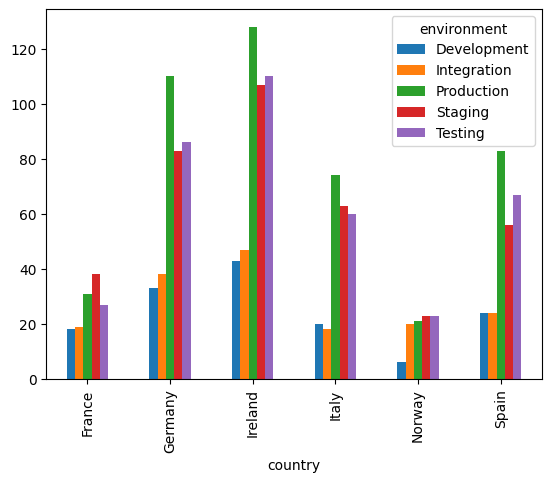

In [12]:
g = df.groupby(['country', 'environment']).size()
g.unstack().plot(kind='bar');

# 11. Crear una figura con 4 gráficos en una malla de 2 filas y 2 columnas

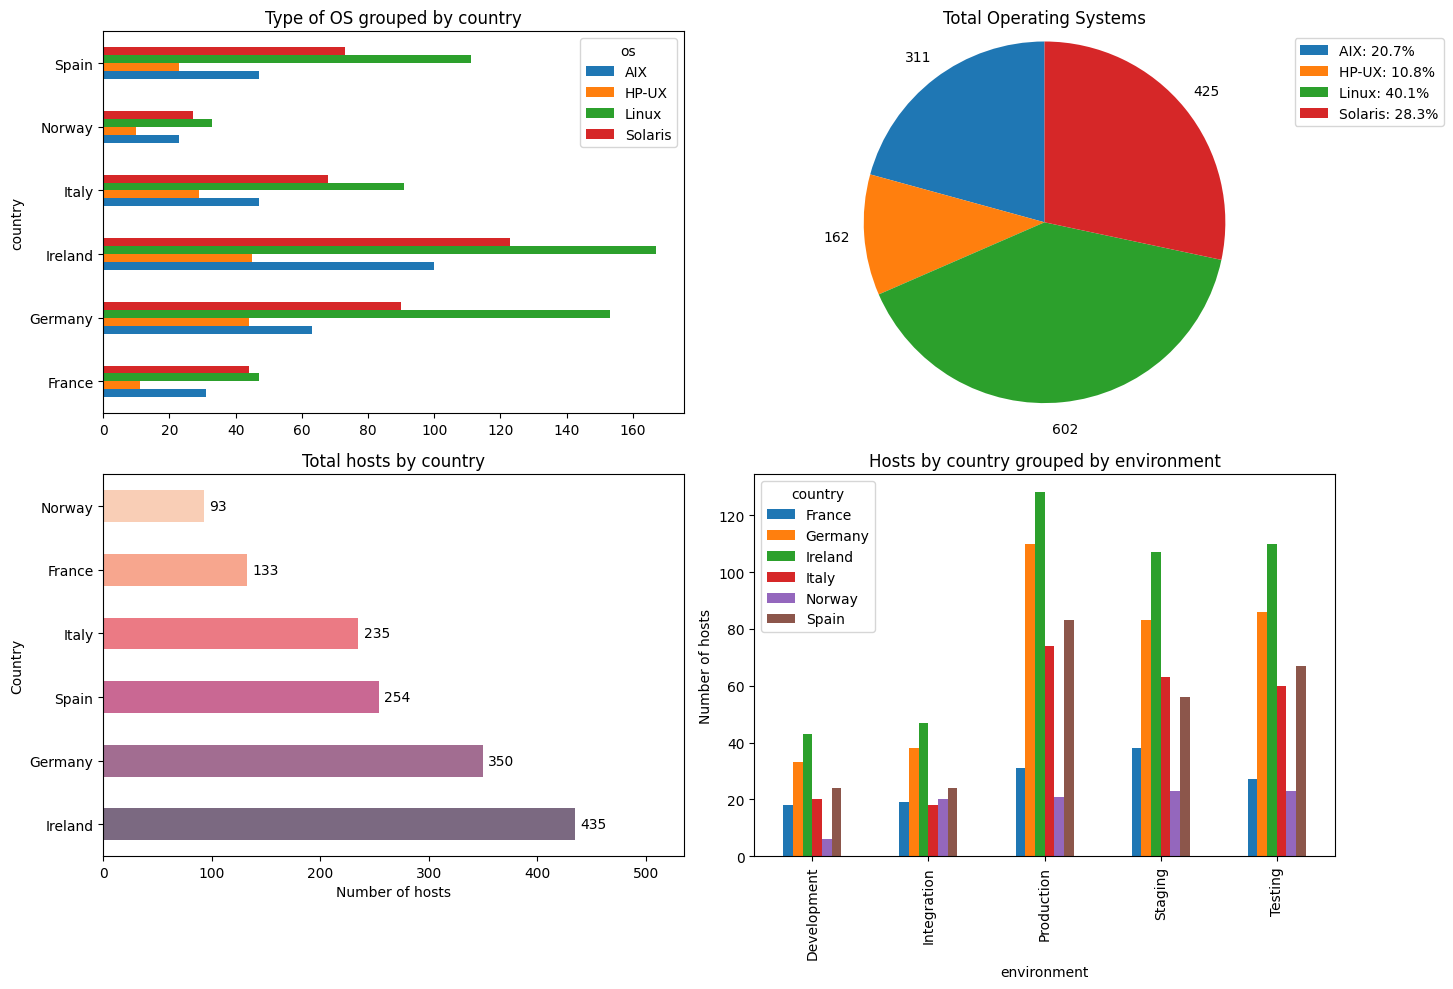

In [41]:
fig, axs = plt.subplots(2, 2, figsize=(14.5, 10))

# PRIMER GRÁFICO
df_hostnames.groupby(['country', 'os']).size().unstack().plot(kind='barh', ax=axs[0,0])
axs[0,0].set_title('Type of OS grouped by country')

# SEGUNDO GRÁFICO
os_counts = df_hostnames.groupby('os').size()
total = os_counts.sum()

def show_counts(pct):
    return f'{int(round(pct / 100. * total))}'

legend_labels = [f'{os}: {(count/total)*100:.1f}%' for os, count in zip(os_counts.index, os_counts)]

wedges, texts, autotexts = axs[0,1].pie(
    os_counts,
    autopct=show_counts,
    startangle=90,
    pctdistance=1.15
)

axs[0,1].legend(
    wedges,
    legend_labels,
    loc="upper right",
    bbox_to_anchor=(1.2, 1)
)

axs[0,1].set_title('Total Operating Systems')
axs[0,1].axis('equal')

# TERCER GRÁFICO
ax = axs[1, 0]

country_counts = df_hostnames['country'].value_counts()

colors = sns.color_palette("rocket", n_colors=len(country_counts))
country_counts.plot(
    kind='barh',
    ax=ax,
    color=colors,
    alpha=0.65
)

ax.set_title('Total hosts by country')
ax.set_xlabel('Number of hosts')
ax.set_ylabel('Country')

for bar in ax.patches:
    width = bar.get_width()
    ax.text(
        width + 5,
        bar.get_y() + bar.get_height() / 2,
        f'{int(width)}',
        ha='left',
        va='center'
    )

max_count = country_counts.max()
ax.set_xlim(0, max_count + 100)

# CUARTO GRÁFICO
df_hostnames.groupby(['country', 'environment']).size().unstack(0).plot(kind='bar', ax=axs[1,1])
axs[1,1].set_title('Hosts by country grouped by environment')
axs[1,1].set_ylabel('Number of hosts')

fig.tight_layout()
plt.show()